In [13]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


After testing the effectiveness of using the MODIS product to classify fires from the GFA dataset, this notebook uses MODIS to classify fires in the MTBS and GFD datasets, which do not originally contain a land cover attribute.

In [14]:
import geopandas as gpd

from wildfire_stats import config as cfg
from wildfire_stats.data import classification as dcls
from wildfire_stats.data import io as dio
from wildfire_stats.data import rasters as drast
from wildfire_stats.fitting import fits as fits
from wildfire_stats.plotting import distributions as pdist
from wildfire_stats.reporting import tables as rtab

P = cfg.load_paths()
MIN_FIRE_SIZE = 6.45  # km²; minimum fire size. Set to 4 to reproduce the earlier analysis
cfg.set_overrides(min_fire=MIN_FIRE_SIZE)  # every library default (xmin, amin_min, ...) follows this
A = cfg.load_assumptions()  # A["min_fire"] == MIN_FIRE_SIZE
MF_TAG = dio.minfire_tag()  # filename tag, e.g. "minfire6p45"

# MTBS subset: "conus", "ak", or "all" (CONUS + AK; HI/PR always excluded)
MTBS_REGION = A["mtbs_region"]
MTBS_TAG = dio.mtbs_tag(MTBS_REGION)  # output filename prefix, e.g. mtbs_all

modis_by_year = drast.index_modis_by_year(P.modis / "GeoTIFF")

### Classify MTBS

In [15]:
mtbs_gdf = dio.load_mtbs(P.mtbs / "S_USA.MTBS_BURN_AREA_BOUNDARY.shp", region=MTBS_REGION)

mtbs_filtered = mtbs_gdf[mtbs_gdf["AREA_SQKM"] >= MIN_FIRE_SIZE].copy()
mtbs_filtered = mtbs_filtered.rename(columns={
    "YEAR": "year",
    "AREA_SQKM": "area_km2"
})

mtbs_classified = dcls.classify_with_modis(mtbs_filtered, "year", modis_by_year, out_col="modis_class")

print(f"Classified {len(mtbs_classified)} MTBS ({MTBS_REGION}) fires over {MIN_FIRE_SIZE} km²")
mtbs_classified[["year", "area_km2", "modis_class"]].head()

Classified 16453 MTBS (all) fires over 6.45 km²


,year,area_km2,modis_class
103,2012,83.589212,Evergreen Needleleaf forest
106,2012,6.700489,Woody savannas
107,2012,8.420656,Evergreen Needleleaf forest
109,2012,1242.073999,Savannas
112,2012,6.635764,Woody savannas


### Classify Idaho GFD

In [16]:
idaho_gdf = dio.load_idaho(P.idaho / "HFD_HistoricFiresDatabase8_0.gdb")

idaho_filtered = idaho_gdf[idaho_gdf["area_km2"] >= MIN_FIRE_SIZE].copy()
idaho_filtered = idaho_filtered.rename(columns={"FIRE_YEAR": "year"})

idaho_classified = dcls.classify_with_modis(idaho_filtered, "year", modis_by_year, out_col="modis_class")

These take a long time to run, so saving them below so you can call them in later.

In [22]:
dio.save_vector(mtbs_classified, P.logged_output / f"{MTBS_TAG}_2003_2016_classified_timevarying_{MF_TAG}.shp")
dio.save_vector(idaho_classified, P.logged_output / f"idaho_2003_2016_classified_timevarying_{MF_TAG}.shp")

# written by notebook 3
gfa_classified = gpd.read_file(P.logged_output / f"gfa_2003_2016_usa_classified_timevarying_{MF_TAG}.shp")

Saved GeoDataFrame to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/logged_output/mtbs_all_2003_2016_classified_timevarying_minfire6p45.shp
Saved GeoDataFrame to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/logged_output/idaho_2003_2016_classified_timevarying_minfire6p45.shp


Now, the following code runs the distribution fitting routine on each land cover type for each dataset.

In [18]:
years = A["modis_years"]

# xmin for every fit = MIN_FIRE_SIZE (via cfg.set_overrides in the setup cell)
# "modis_clas": the shapefile round-trip truncates GFA's modis_class column name
results_gfa = fits.fit_static_by_group(gfa_classified, "modis_clas", years=years)
results_idaho = fits.fit_static_by_group(idaho_classified, "modis_class", years=years)
results_mtbs = fits.fit_static_by_group(mtbs_classified, "modis_class", years=years)

dio.save_pickle(results_gfa, P.output / f"gfa_static_fits_by_biome_2003_2016_{MF_TAG}.pkl")
dio.save_pickle(results_mtbs, P.output / f"{MTBS_TAG}_static_fits_by_biome_2003_2016_{MF_TAG}.pkl")
dio.save_pickle(results_idaho, P.output / f"idaho_static_fits_by_biome_2003_2016_{MF_TAG}.pkl")


=== Barren or sparsely vegetated (n=18) ===
there are 18 points above xmin 6.45 km^2

=== Closed shrublands (n=106) ===
there are 106 points above xmin 6.45 km^2

=== Croplands (n=3165) ===
there are 3165 points above xmin 6.45 km^2

=== Deciduous Broadleaf forest (n=315) ===
there are 315 points above xmin 6.45 km^2

=== Evergreen Broadleaf forest (n=251) ===
there are 251 points above xmin 6.45 km^2

=== Evergreen Needleleaf forest (n=394) ===
there are 394 points above xmin 6.45 km^2

=== Grasslands (n=4172) ===
there are 4172 points above xmin 6.45 km^2

=== Mixed forest (n=98) ===
there are 98 points above xmin 6.45 km^2

=== Open shrublands (n=354) ===
there are 354 points above xmin 6.45 km^2

=== Other (n=27) ===
there are 27 points above xmin 6.45 km^2

=== Savannas (n=1304) ===
there are 1304 points above xmin 6.45 km^2

=== Urban and built-up (n=5) ===
there are 5 points above xmin 6.45 km^2

=== Woody savannas (n=1465) ===
there are 1465 points above xmin 6.45 km^2

=== Ba

The following table summarizes the "good" fits for each dataset+land cover type. Good fits are ones fit on >400 fires, loglikelihood relative to the best fit is <=2.0, and they do not reduce to a simpler distribution with 95% confidence. This includes an additional filter to remove fits where the relative error on a parameter was too big, but that max_rel_error constraint was not used in future analysis.

In [19]:
results_dicts = {
    "GFA": results_gfa,
    "Idaho": results_idaho,
    "MTBS": results_mtbs
}

counts_dicts = {
    "GFA": gfa_classified[(gfa_classified["year"].between(*years)) & (gfa_classified["area_km2"] >= MIN_FIRE_SIZE)]["modis_clas"].value_counts(),
    "Idaho": idaho_classified[(idaho_classified["year"].between(*years)) & (idaho_classified["area_km2"] >= MIN_FIRE_SIZE)]["modis_class"].value_counts(),
    "MTBS": mtbs_classified[(mtbs_classified["year"].between(*years)) & (mtbs_classified["area_km2"] >= MIN_FIRE_SIZE)]["modis_class"].value_counts(),
}

rtab.build_comparison_table(results_dicts, counts_dicts)

,modis_class,MTBS_n,MTBS_fit,MTBS_loglik,MTBS_reduces_to,GFA_n,GFA_fit,GFA_loglik,GFA_reduces_to,Idaho_n,Idaho_fit,Idaho_loglik,Idaho_reduces_to
0,Croplands,,,,,3165,generalized_pareto,,,,,,
1,,,,,,,lognormal,1.252,,,,,
2,Deciduous Broadleaf forest,440,truncated_power_law,,,,,,,,,,
3,,,generalized_pareto,0.173,,,,,,,,,
4,Evergreen Broadleaf forest,492,generalized_pareto,,,,,,,,,,
5,Evergreen Needleleaf forest,425,truncated_power_law,,,,,,,,,,
6,Grasslands,2981,truncated_power_law,,,4172,lognormal,,,2100,truncated_power_law,0.917,
7,,,,,,,generalized_pareto,1.448,,,lognormal,1.814,
8,Open shrublands,403,lognormal,0.587,,,,,,,,,
9,,,truncated_power_law,1.194,,,,,,,,,


The following function visualizes the "good" fits in parameter space for a all datasets and land cover types.

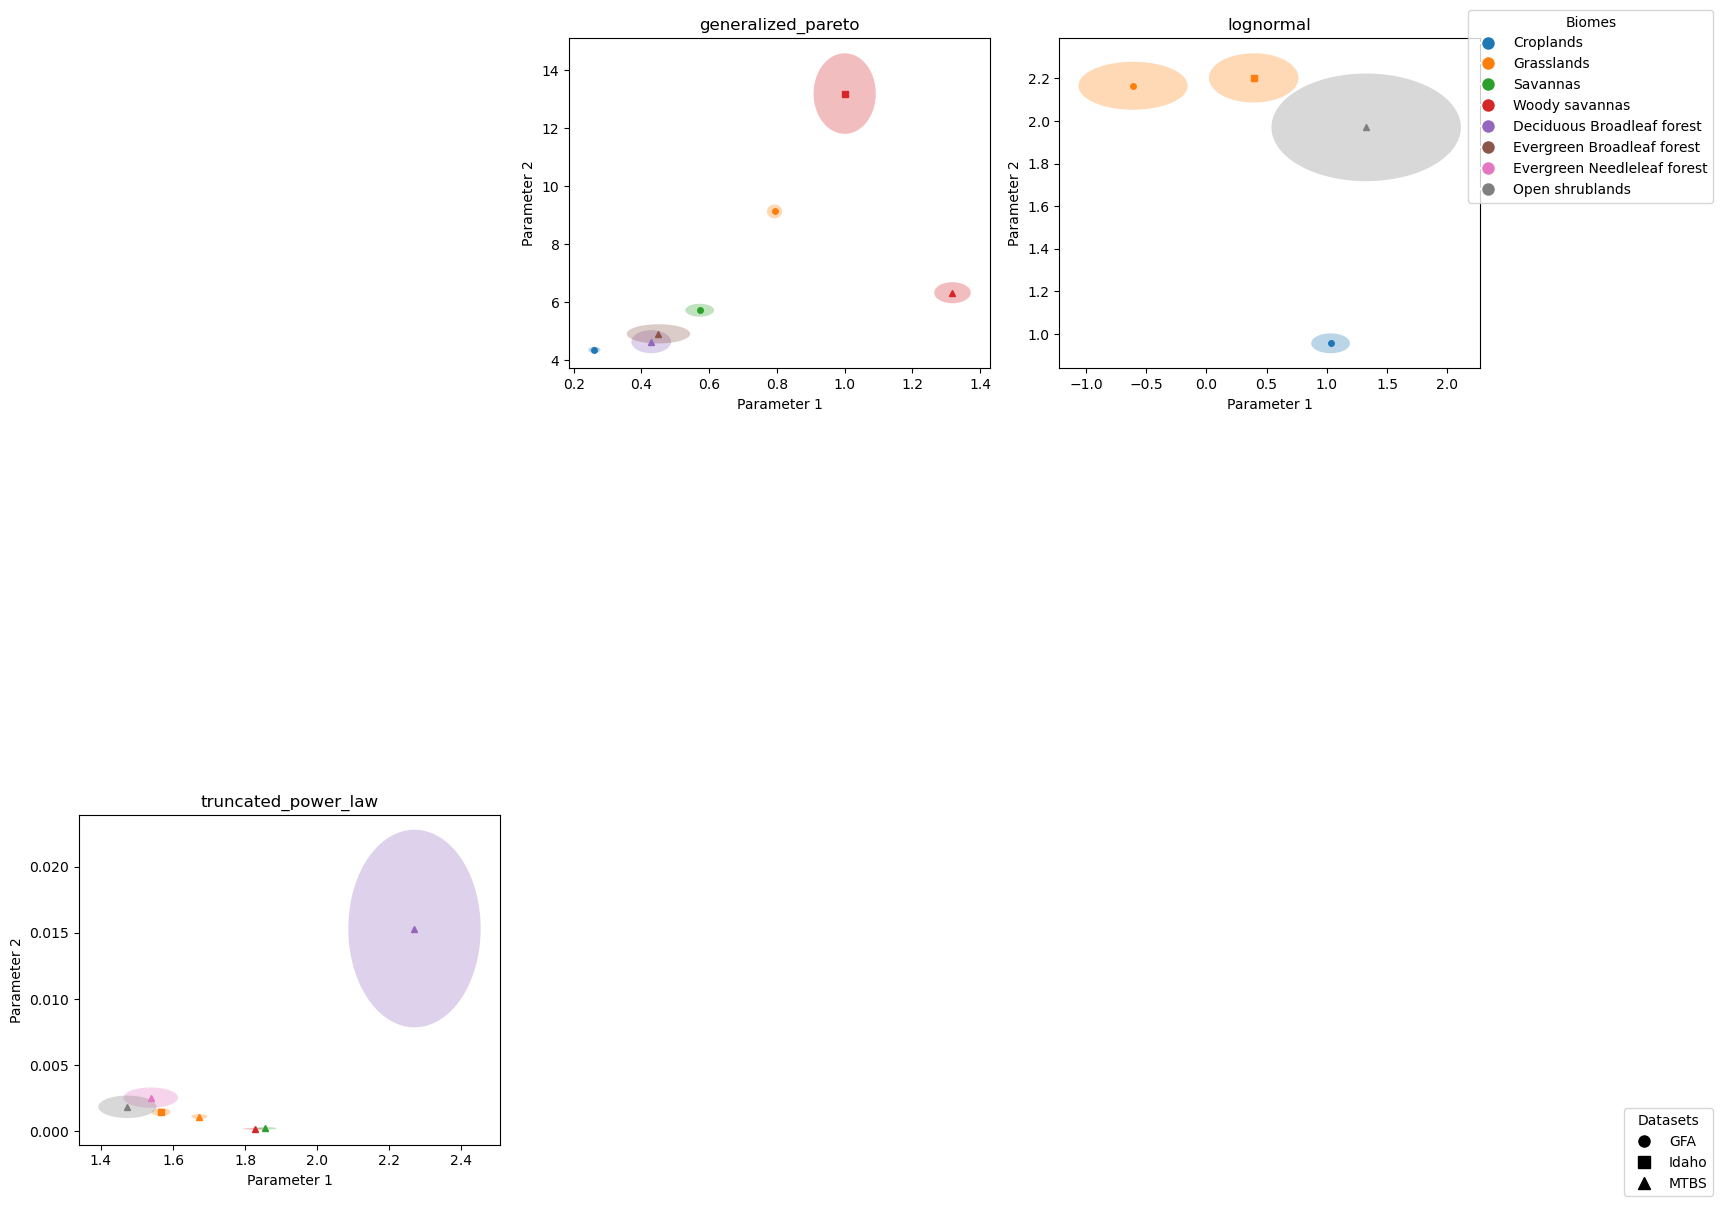

In [20]:
pdist.plot_distribution_params(results_dicts, counts_dicts, log_axes=False)

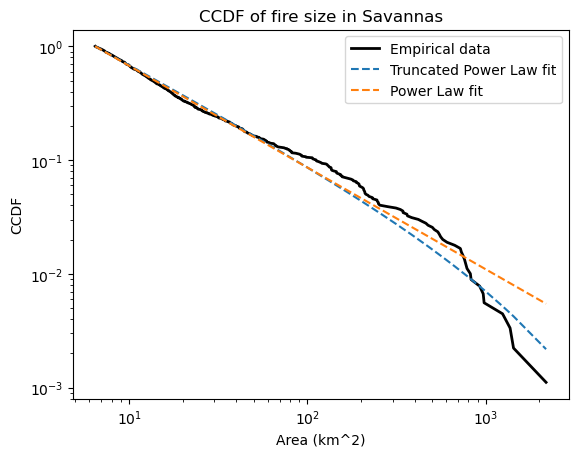

<Axes: title={'center': 'CCDF of fire size in Savannas'}, xlabel='Area (km^2)', ylabel='CCDF'>

In [21]:
pdist.plot_modis_category_ccdf(mtbs_classified, "Savannas", which=["truncated_power_law", "power_law"])